## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams. 

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [1]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 

**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Vivian Le

**Date:** 10/21/2026

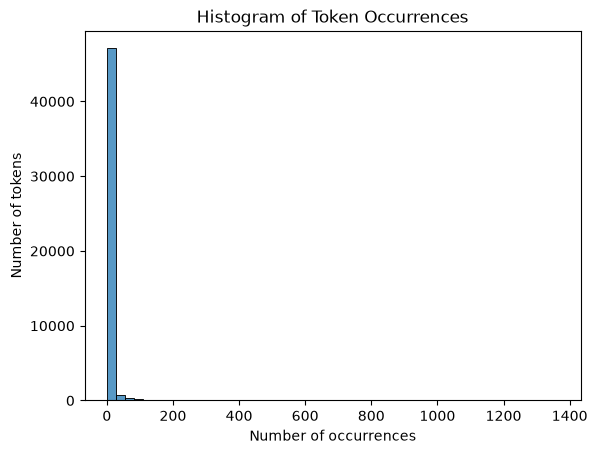

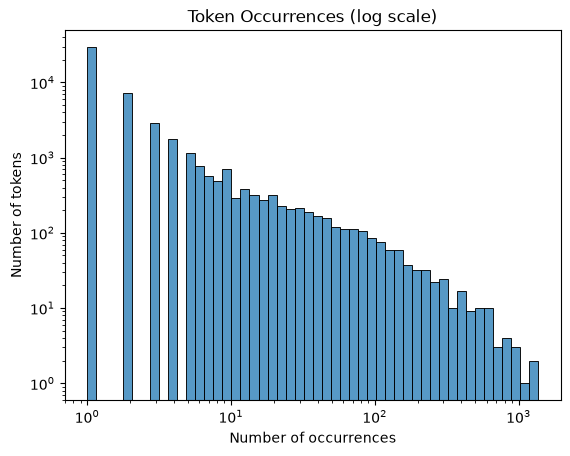

count    48691.000000
mean         5.687889
std         27.717476
min          1.000000
25%          1.000000
50%          1.000000
75%          2.000000
max       1365.000000
Name: count, dtype: float64
Share of tokens appearing once: 60.4%


In [2]:
# Your Phase 1 solution to the problem goes here.

# Q1.

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.DataFrame(token_freq, columns=['token', 'count'])

sns.histplot(df['count'], bins=50)
plt.title('Histogram of Token Occurrences')
plt.xlabel('Number of occurrences')
plt.ylabel('Number of tokens')
plt.show()

sns.histplot(df['count'], bins=50, log_scale=True)
plt.yscale('log')
plt.title('Token Occurrences (log scale)')
plt.xlabel('Number of occurrences')
plt.ylabel('Number of tokens')
plt.show()

print(df['count'].describe())
print(f"Share of tokens appearing once: {(df['count'] == 1).mean():.1%}")


Q1. The frequency distribution of the tokens is strongly right-skewed. On the regular histogram, almost all tokens fall into the first bar, with a long, flat tail stretching up to around 1,400. Most tokens are rare: the median token appears only once, about 60% of the 48,691 unique tokens appear exactly once, and 75% appear twice or less. A few tokens, such as "new," "date," "get," and "please," appear more than 1,000 times each, which pulls the average up to around 5.7. On a log scale, the histogram looks close to a straight line with a negative slope. This is a power-law pattern, consistent with Zipf's law: a few words are used constantly, while most words are used only once or twice. For machine learning, this means most tokens are too rare to be useful as individual features, and the frequent tokens carry most of the information.

In [3]:
# Q2.

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

df = pd.read_parquet('data/Phishing_clean.parquet')

y = df['Email Type']
X = df.drop('Email Type', axis=1)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=100)

reg = LinearRegression().fit(X_train, y_train)

print('Train R^2:', reg.score(X_train, y_train))
print('Test R^2:', reg.score(X_test, y_test))

results = pd.DataFrame({'variable': X.columns, 'coefficient': reg.coef_})
results['abs_coefficient'] = results['coefficient'].abs()
results.sort_values('abs_coefficient', ascending=False).head(15)

Train R^2: 0.7680301260237321
Test R^2: 0.6587519780798341


,variable,coefficient,abs_coefficient
1504,background-image:,-0.891476,0.891476
740,localized,0.815698,0.815698
1406,"helvetica,",0.717349,0.717349
2362,thermal,0.706216,0.706216
906,aging,0.622411,0.622411
2566,transcript,0.578132,0.578132
2559,april's,-0.546313,0.546313
1494,retrieving,-0.527824,0.527824
818,cnet,-0.510492,0.510492
2657,zdnet,-0.503465,0.503465


Q2. After a 80/20 train-test split, the linear regression of Email Type on the 2,711 one-hot-encoded tokens has an R^2 of 0.768 on the training set and 0.659 on the test set. The model explains a fair amount of the variation in whether an email is a scam, but it does noticeably worse on unseen data, which suggests some overfitting from using so many features. The words that have the largest coefficients in terms of absolute values are "background-image:" (-0.89), "localized" (0.82), "helvetica," (0.72), "thermal" (0.72), "thermal" (0.71), "aging" (0.62), "transcript" (0.58), "april's (-0.55), "retrieving" (-0.53), "cnet" (-0.51), "zdnet" (-0.50), and "xanaax" (0.50). Positive coefficients move the prediction toward the category of scam, while negative coefficients move it toward the category of not scam. The majority of these terms do not seem to be obviously associated with scams. Most of them are either HTML/CSS formatting terms to be obviously associated with scams. Most of them are either HTML/CSS formatting terms ("background-image:", "helvetica,") or infrequent words, which occur in only about 10 to 60 emails. As these terms of infrequent, the model can attribute very large coefficients to them to explain some specific emails, so they have a high impact on predictions but are probably not robust predictors. One exception is the misspelling "xanaax," which is typical for spam.

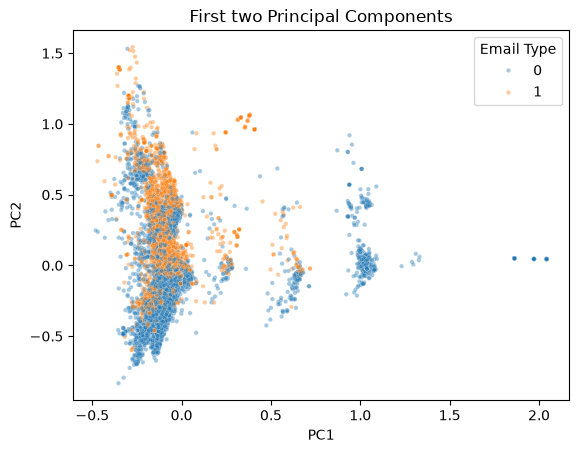

Explained variance ratio: [0.01113087 0.00861127]
date         0.673935
url:         0.367382
start        0.287562
hour         0.260531
hourahead    0.255636
ancillary    0.194690
schedules    0.194326
required     0.063287
Name: PC1, dtype: float64
new         0.448257
like        0.418008
would       0.321294
get         0.312658
hello       0.142952
offer       0.133909
software    0.123364
one         0.116750
Name: PC2, dtype: float64
please     -0.199928
message    -0.151588
attached   -0.136024
call       -0.135040
enron      -0.113411
Name: PC2, dtype: float64


In [4]:
#Q3.

from sklearn.decomposition import PCA
import seaborn as sns
import matplotlib.pyplot as plt

pca = PCA(n_components=2)
Z = pca.fit_transform(X)

pc = pd.DataFrame(Z, columns = ['PC1', 'PC2'])
pc['Email Type'] = y.values

sns.scatterplot(data=pc, x='PC1', y='PC2', hue='Email Type', alpha=0.4, s=10)
plt.title('First two Principal Components')
plt.show()

print('Explained variance ratio:', pca.explained_variance_ratio_)

loadings = pd.DataFrame(pca.components_.T, index=X.columns, columns=['PC1', 'PC2'])
print(loadings['PC1'].sort_values(ascending=False).head(8))
print(loadings['PC2'].sort_values(ascending=False).head(8))
print(loadings['PC2'].sort_values().head(5))

Q3.

The scatter plot shows some separation between phishing and non-phishing emails, but a lot of overlap. Most emails of both types sit in one dense cloud near PC1 ≈ 0. Within that cloud, phishing emails (orange) tend to have higher PC2 values and legitimate emails (blue) tend to have lower PC2 values. Along PC1, the long tail to the right is almost entirely legitimate emails, which form several distinct vertical clusters around PC1 ≈ 0.6, 1.0, and 2.0. Phishing emails almost never have large PC1 values. Looking at the loadings explains this. PC1 is driven mostly by "date," "url:," "start," "hour," "hourahead," "ancillary," and "schedules," which are words from automated Enron energy-scheduling emails, so the clusters on the right are groups of near-identical legitimate business emails. PC2 is positive for "new," "like," "get," "would," "hello," "offer," and "software," which are common in sales or spam emails, and negative for "please," "message," "call," "attached," and "enron," which are common in workplace emails. That is why scams sit higher on PC2. However, these two components account for only about 2% of the total variance in the token data (1.1% and 0.9%), so they capture only a small part of the information in the 2,711 tokens. Principal Component Analysis is an unsupervised approach, so the components do not use the labels and are not chosen to separate scams from legitimate emails; any separation we see is a side effect of differences in word usage.

In [5]:
# Q4.

from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression

X_train32 = X_train.astype('float32')
X_test32 = X_test.astype('float32')

pca = PCA(n_components=2610)
Z_train = pca.fit_transform(X_train32)
Z_test = pca.transform(X_test32)

reg_pca = LinearRegression().fit(Z_train, y_train)

print('Train R^2:', reg_pca.score(Z_train, y_train))
print('Test R^2:', reg_pca.score(Z_test, y_test))
print('Variance explained by 2,610 PCs:', pca.explained_variance_ratio_.sum())

Train R^2: 0.767333447933197
Test R^2: 0.659709632396698
Variance explained by 2,610 PCs: 0.99984914


Q4.

Using the first 2610 principal components, the linear regression has an R^2 of 0.767 on the training set and 0.660 on the test set. This is almost identical to the original linear regression on all 2711 tokens (0.768 train, 0.659 test). The 2610 components account for 99.98% of the variance in the token data, so they hold almost all the information contained in the original set of features. The roughly 100 components that were dropped hold only a tiny, almost negligible fraction of the variance. So using PCA here does not improve performance. It only changes the organization of the existing data to create a completely new set of features. It still suffers from overfitting just like before, because the gap between training and test R^2 is the same, at approximately 0.11. PCA would only help if we kept far fewer components, trading a small loss in training fit for a simpler model that might generalize better. A drawback of the PCA version is that the coefficients are on components rather than words, so they are much harder to interpret than the word coefficients in Q2. In addition, the default PCA ran out of memory on my computer, so I converted the data to float32 first, which uses half the memory and gives the same results. covariance matrix.

Q5.

The main advantage is that principal components are uncorrelated, while many of the original tokens are strongly correlated (for example, "date," "hour," and "hourahead" often appear together in automated Enron emails). Because the variables are correlated, the regression estimates become unstable, but since the components are orthogonal to each other, this problem disappears.Also, the components are ranked according to the amount of variance explained, so only the most important components can be retained, and the other components can be ignored, since they mainly contain noise contributed by the rare words. This makes the model even more simple and less likely to overfit. In contrast, with the original data, there is no straightforward way of choosing which tokens to remove. In Q4 we kept almost all the components, so results barely changed; the real benefit comes from keeping far fewer.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [6]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]